In [1]:
import sys  
sys.path.insert(0, '..')

from helper.golbal_variables import * 

import random
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

In [2]:
STEM_NAMES = ["bass", "drums", "vocals", "other"]   # same order as STEM_KEYS in the dataset file
FRAME_SEC = 0.01                                     # AST: 10 ms per frame -> 1024 frames = 10.24 s

FC = GENRES_PT / "flattened_clean"
FA = GENRES_PT / "flattened_augmented"
GA = GENRES_PT / "grouped_augmented"

In [3]:
def load_items(path):
    spec, label, stem_id = torch.load(path, map_location="cpu")
    return spec.float(), int(label), int(stem_id)

def list_files(variant_dir, genre=None):
    variant_dir = Path(variant_dir)
    pattern = f"{genre}/*.pt" if genre else "*/*.pt"
    return sorted(variant_dir.glob(pattern))

def _show(ax, spec, title):
    """spec [1024,128] (time x mel) -> image with mel on y axis, seconds on x axis."""
    ax.imshow(
        spec.numpy().T, 
        origin="lower", 
        aspect="auto",
        extent=[0, spec.shape[0] * FRAME_SEC, 0, spec.shape[1]], 
        cmap="magma"
    )
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("time (s)")
    ax.set_ylabel("mel bin")

In [4]:
def plot_one(path):
    spec, label, stem_id = load_items(path)
    if spec.dim() == 2:
        fig, ax = plt.subplots(figsize=(10, 3.5))
        name = STEM_NAMES[stem_id] if stem_id >= 0 else "mix"
        _show(ax, spec, f"{Path(path).parent.name} | {name} | {Path(path).name}")
    else:  # grouped: [4, 1024, 128]
        fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
        for k, ax in enumerate(axes):
            _show(ax, spec[k], f"{Path(path).parent.name} | {STEM_NAMES[k]}")
    plt.tight_layout()
    plt.show()

In [5]:
def plot_clean_vs_augmented(clean_dir, aug_dir, genre=None, n=3, seed=0):
    """
    Works because both variants use the same index order, so chunk_{i}_... in
    the clean folder is the same song/chunk/stem as in the augmented folder.
    A bright difference panel shows where ESC-50 noise was added.
    """
    random.seed(seed)
    clean_files = list_files(clean_dir, genre)
    picks = random.sample(clean_files, min(n, len(clean_files)))

    fig, axes = plt.subplots(len(picks), 3, figsize=(16, 3.2 * len(picks)))
    axes = np.atleast_2d(axes)

    for row, cpath in enumerate(picks):
        apath = Path(aug_dir) / cpath.parent.name / cpath.name
        if not apath.exists():
            print("missing augmented file:", apath)
            continue
        clean, _, stem_id = load_items(cpath)
        aug, _, _ = load_items(apath)
        if clean.dim() == 3:          # grouped: show stem 0 only, use plot_one for all stems
            clean, aug = clean[0], aug[0]
        name = STEM_NAMES[stem_id] if stem_id >= 0 else "stem 0"
        _show(axes[row, 0], clean, f"clean | {cpath.parent.name} | {name}")
        _show(axes[row, 1], aug, "augmented")
        _show(axes[row, 2], (aug - clean).abs(), "|augmented - clean|")
    plt.tight_layout()
    plt.show()


In [6]:
def plot_stems_of_one_chunk(variant_dir, genre, seed=0):
    """For the flattened variants: finds the 4 stem files of one (song, chunk) and stacks them."""
    random.seed(seed)
    files = list_files(variant_dir, genre)
    groups = {}
    for f in files:
        m = re.match(r"chunk_(\d+)_c(\d+)_s(\d+)", f.stem)
        if not m:
            continue
        # items of one (song, chunk) have consecutive indices i..i+3, stem ids 0..3
        i, c, s = map(int, m.groups())
        groups.setdefault((i - s, c), {})[s] = f

    complete = [g for g in groups.values() if len(g) == 4]
    if not complete:
        print("no complete 4-stem groups found (is this a flattened variant?)")
        return
    group = random.choice(complete)

    fig, axes = plt.subplots(4, 1, figsize=(10, 10), sharex=True)
    for s in range(4):
        spec, _, _ = load_items(group[s])
        _show(axes[s], spec, f"{genre} | {STEM_NAMES[s]}")
    plt.tight_layout()
    plt.show()

In [7]:
def plot_class_balance(variant_dir):
    counts = Counter(f.parent.name for f in list_files(variant_dir))
    names = sorted(counts)
    plt.figure(figsize=(9, 3.5))
    plt.bar(names, [counts[n] for n in names])
    plt.xticks(rotation=45)
    plt.title(f"files per genre ({sum(counts.values())} total)")
    plt.tight_layout()
    plt.show()
    return counts

In [8]:
def plot_mean_profiles(variant_dir, per_genre_limit=150, seed=0):
    """
    Average over time -> a 128-bin frequency profile.
    One line per genre (flattened variants: one subplot per stem).
    Quick check that stems really look different and genres are separable.
    """
    random.seed(seed)
    variant_dir = Path(variant_dir)
    profiles = {}  # (stem_id, genre) -> list of [128] vectors

    for genre_dir in sorted(p for p in variant_dir.iterdir() if p.is_dir()):
        files = sorted(genre_dir.glob("*.pt"))
        files = random.sample(files, min(per_genre_limit, len(files)))
        for f in files:
            spec, _, stem_id = load_items(f)
            if spec.dim() == 3:   # grouped
                for k in range(spec.shape[0]):
                    profiles.setdefault((k, genre_dir.name), []).append(spec[k].mean(0).numpy())
            else:
                profiles.setdefault((max(stem_id, 0), genre_dir.name), []).append(spec.mean(0).numpy())

    stems = sorted({k[0] for k in profiles})
    fig, axes = plt.subplots(1, len(stems), figsize=(4.5 * len(stems), 3.8), sharey=True, squeeze=False)
    for ax, s in zip(axes[0], stems):
        for (st, genre), vecs in sorted(profiles.items()):
            if st == s:
                ax.plot(np.mean(vecs, axis=0), label=genre, lw=1)
        ax.set_title(STEM_NAMES[s] if len(stems) > 1 else "mix")
        ax.set_xlabel("mel bin")
    axes[0][0].set_ylabel("mean normalised fbank")
    axes[0][-1].legend(fontsize=7, ncol=2)
    plt.tight_layout()
    plt.show()

In [9]:
VARIANTS = ["flattened_clean", "flattened_augmented", "grouped_clean", "grouped_augmented"]

def _genres_in(variant_dir):
    return sorted(p.name for p in Path(variant_dir).iterdir() if p.is_dir())

def _specs_for(variant_dir, genre, seed=0):
    """
    Returns 4 spectrograms [1024,128] (bass, drums, vocals, other) from ONE song chunk.
    The pick is deterministic per (seed, genre), so clean and augmented variants
    show the very same chunk as long as they contain the same file names.
    """
    files = list_files(variant_dir, genre)
    if not files:
        raise FileNotFoundError(f"no .pt files for genre '{genre}' in {variant_dir}")
    rng = random.Random(f"{seed}-{genre}")

    first, _, _ = load_items(files[0])
    if first.dim() == 3:  # grouped: one file already holds all 4 stems
        spec, _, _ = load_items(rng.choice(files))
        return [spec[k] for k in range(4)]

    groups = {}  # flattened: items of one (song, chunk) have consecutive ids i..i+3, stems 0..3
    for f in files:
        m = re.match(r"chunk_(\d+)_c(\d+)_s(\d+)", f.stem)
        if m:
            i, c, s = map(int, m.groups())
            groups.setdefault((i - s, c), {})[s] = f
    complete = sorted(k for k, g in groups.items() if len(g) == 4)
    key = rng.choice(complete)
    return [load_items(groups[key][s])[0] for s in range(4)]

def _range(spec_lists, lo=1, hi=99):
    vals = np.concatenate([s.numpy().ravel()[::50] for specs in spec_lists for s in specs])
    return float(np.percentile(vals, lo)), float(np.percentile(vals, hi))

def _draw(ax, spec, vmin, vmax):
    return ax.imshow(
        spec.numpy().T, 
        origin="lower", 
        aspect="auto", 
        cmap="magma", 
        vmin=vmin, 
        vmax=vmax,
        extent=[0, spec.shape[0] * FRAME_SEC, 0, spec.shape[1]]
    )

def _finish(fig, save_path, show):
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=120, bbox_inches="tight")
        print("saved:", save_path)
    if show:
        plt.show()
    else:
        plt.close(fig)

In [10]:
def plot_genre_stem_grid(variant_dir, genres=None, seed=0, vmin=None, vmax=None,
                         save_path=None, show=True, title=None):
    """
    Rows = genres, columns = 4 stems, one shared color scale -> easy visual comparison.
    Returns (vmin, vmax) so the same scale can be reused for other variants.
    """
    genres = genres or _genres_in(variant_dir)
    data = {g: _specs_for(variant_dir, g, seed) for g in genres}
    if vmin is None or vmax is None:
        vmin, vmax = _range(data.values())

    n = len(genres)
    fig, axes = plt.subplots(n, 4, figsize=(16, 1.8 * n + 0.6), sharex=True, sharey=True, squeeze=False)
    fig.subplots_adjust(wspace=0.02, hspace=0.05, top=0.955, bottom=0.04)

    for r, g in enumerate(genres):
        for c in range(4):
            im = _draw(axes[r, c], data[g][c], vmin, vmax)
            if r == 0:
                axes[r, c].set_title(STEM_NAMES[c], fontsize=11)
            if c == 0:
                axes[r, c].set_ylabel(g, fontsize=10, rotation=0, ha="right", va="center", labelpad=8)
            if r < n - 1:
                axes[r, c].tick_params(labelbottom=False)
            if c > 0:
                axes[r, c].tick_params(labelleft=False)
    for c in range(4):
        axes[-1, c].set_xlabel("time (s)")

    fig.suptitle(title or Path(variant_dir).name, fontsize=13, y=0.985)
    fig.colorbar(im, ax=axes, fraction=0.012, pad=0.01)
    _finish(fig, save_path, show)
    return vmin, vmax


def plot_clean_vs_aug_grid(clean_dir, aug_dir, genres=None, seed=0, vmin=None, vmax=None, save_path=None, show=True, title=None):
    """Rows = genres, columns = 4 clean stems | 4 augmented stems (same chunk, same color scale)."""
    genres = genres or _genres_in(clean_dir)
    clean = {g: _specs_for(clean_dir, g, seed) for g in genres}
    aug = {g: _specs_for(aug_dir, g, seed) for g in genres}
    if vmin is None or vmax is None:
        vmin, vmax = _range(list(clean.values()) + list(aug.values()))

    n = len(genres)
    fig, axes = plt.subplots(n, 8, figsize=(26, 1.8 * n + 0.6), sharex=True, sharey=True, squeeze=False)
    fig.subplots_adjust(wspace=0.02, hspace=0.05, top=0.955, bottom=0.04)

    for r, g in enumerate(genres):
        for c in range(8):
            spec = clean[g][c] if c < 4 else aug[g][c - 4]
            im = _draw(axes[r, c], spec, vmin, vmax)
            if r == 0:
                tag = "clean" if c < 4 else "aug"
                axes[r, c].set_title(f"{tag} | {STEM_NAMES[c % 4]}", fontsize=10)
            if c == 0:
                axes[r, c].set_ylabel(g, fontsize=10, rotation=0, ha="right", va="center", labelpad=8)
            if r < n - 1:
                axes[r, c].tick_params(labelbottom=False)
            if c > 0:
                axes[r, c].tick_params(labelleft=False)
        axes[r, 4].spines["left"].set_linewidth(3)   # visual divider between clean and augmented

    fig.suptitle(title or f"{Path(clean_dir).name}  vs  {Path(aug_dir).name}", fontsize=13, y=0.985)
    fig.colorbar(im, ax=axes, fraction=0.008, pad=0.01)
    _finish(fig, save_path, show)
    return vmin, vmax

In [11]:
def run_all(genres_pt_dir, out_dir="eda_plots", seed=0, show=False):
    """
    Saves one genre x stem grid per variant, plus clean-vs-augmented grids
    for the flattened and grouped versions. One shared color scale for everything.
    """
    genres_pt_dir, out_dir = Path(genres_pt_dir), Path(out_dir)
    available = [v for v in VARIANTS if (genres_pt_dir / v).exists()]

    vmin = vmax = None
    for v in available:
        vmin_v, vmax_v = plot_genre_stem_grid(genres_pt_dir / v, seed=seed, vmin=vmin, vmax=vmax,
                                              save_path=out_dir / f"{v}.png", show=show)
        if vmin is None:           # first variant sets the common scale
            vmin, vmax = vmin_v, vmax_v

    for kind in ("flattened", "grouped"):
        c, a = genres_pt_dir / f"{kind}_clean", genres_pt_dir / f"{kind}_augmented"
        if c.exists() and a.exists():
            plot_clean_vs_aug_grid(c, a, seed=seed, vmin=vmin, vmax=vmax,
                                   save_path=out_dir / f"{kind}_clean_vs_augmented.png", show=show)

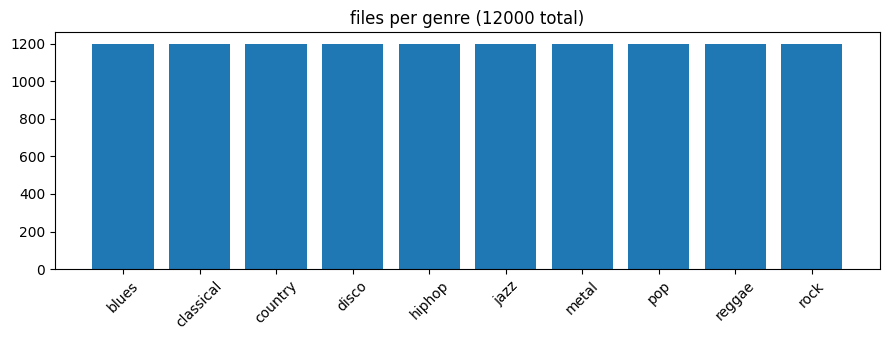

Counter({'blues': 1200,
         'classical': 1200,
         'country': 1200,
         'disco': 1200,
         'hiphop': 1200,
         'jazz': 1200,
         'metal': 1200,
         'pop': 1200,
         'reggae': 1200,
         'rock': 1200})

In [12]:
plot_class_balance(FC)

/tmp/ipykernel_365307/4034304327.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  spec, label, stem_id = torch.load(path, map_location="cpu")


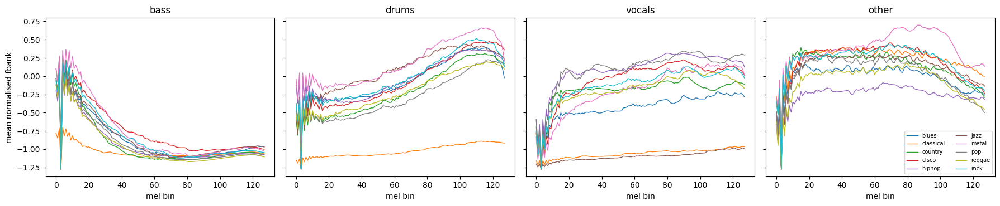

In [13]:
plot_mean_profiles(FC)

## Genre x stem grids (shared color scale)
One tight grid per variant: rows = genres, columns = bass / drums / vocals / other. The old per-genre loop above is kept; you can delete it once you prefer the grids.

/tmp/ipykernel_365307/4034304327.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  spec, label, stem_id = torch.load(path, map_location="cpu")


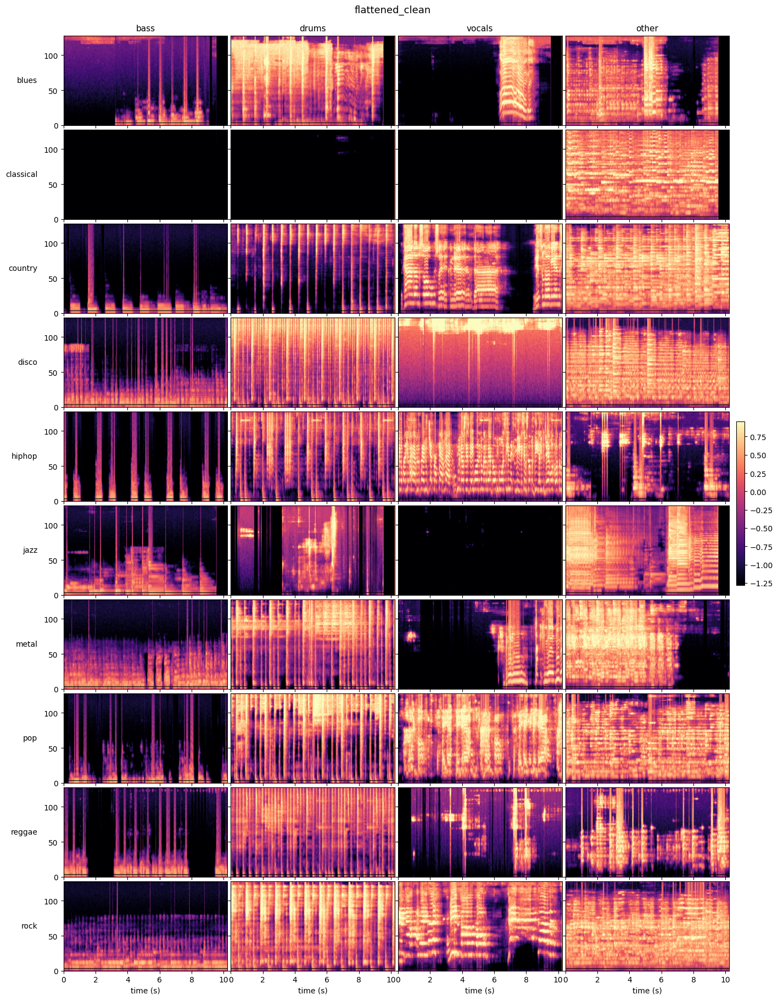

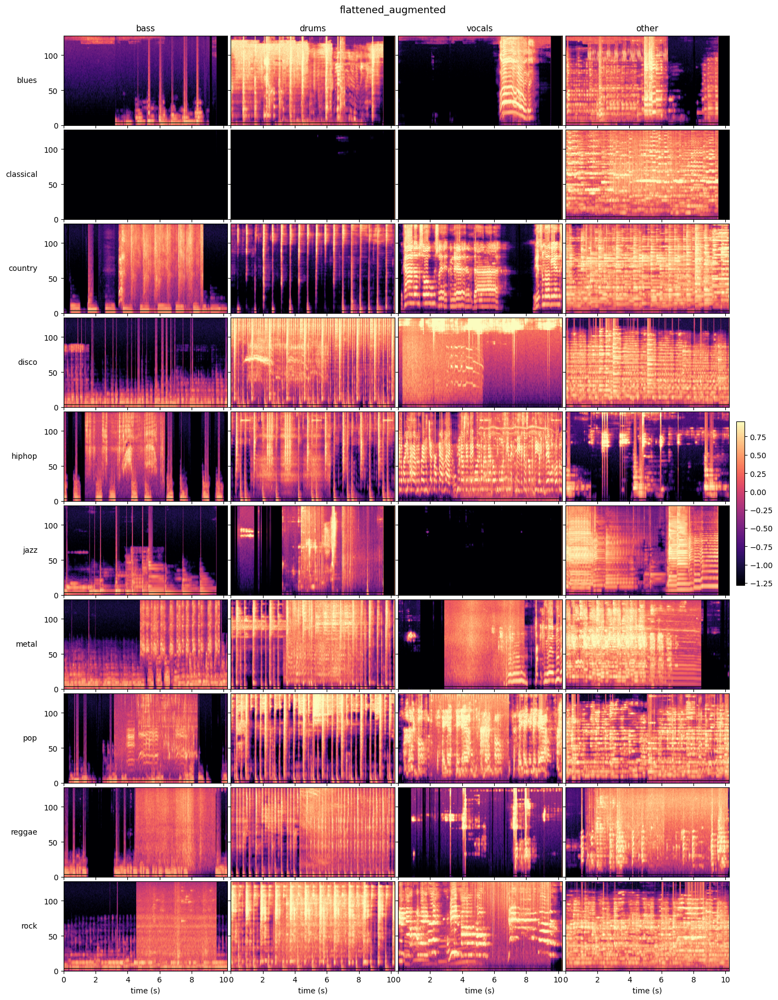

(-1.27734375, 0.95654296875)

In [14]:
# 1) clean flattened grid sets the color scale, the others reuse it so brightness is comparable
vmin, vmax = plot_genre_stem_grid(FC, title="flattened_clean")
plot_genre_stem_grid(FA, vmin=vmin, vmax=vmax, title="flattened_augmented")

/tmp/ipykernel_365307/4034304327.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  spec, label, stem_id = torch.load(path, map_location="cpu")


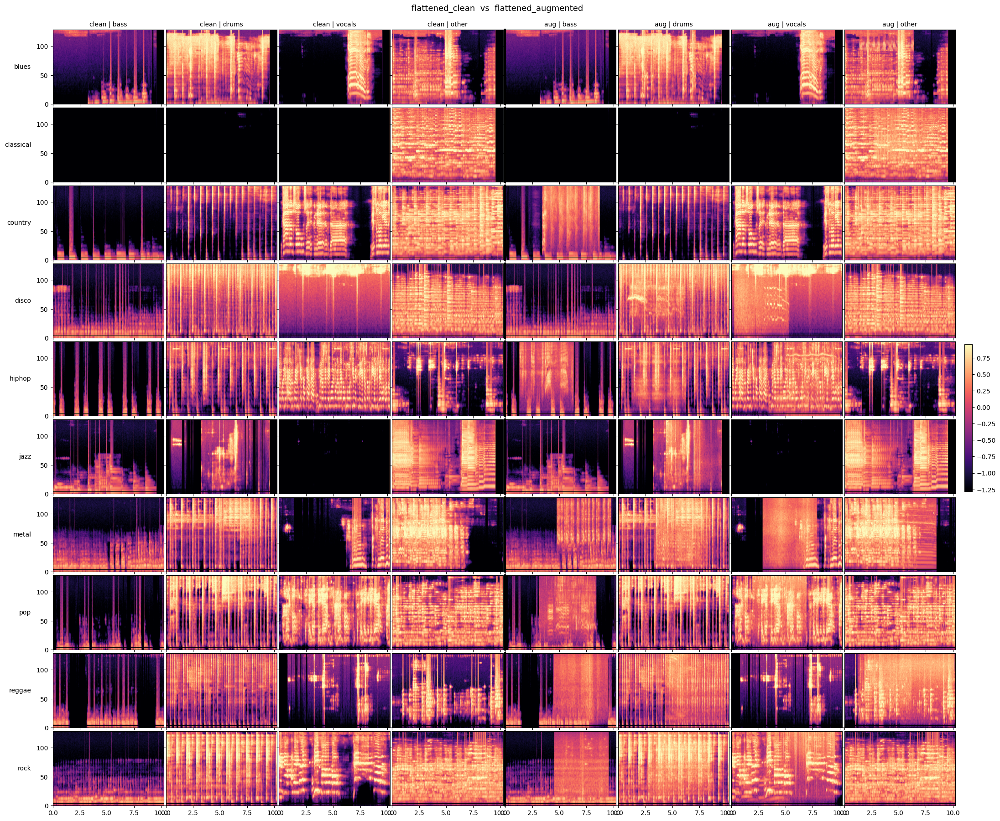

(-1.27734375, 0.95654296875)

In [15]:
# 2) clean | augmented side by side (same song chunk) for all genres
plot_clean_vs_aug_grid(FC, FA, vmin=vmin, vmax=vmax)

/tmp/ipykernel_365307/4034304327.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  spec, label, stem_id = torch.load(path, map_location="cpu")


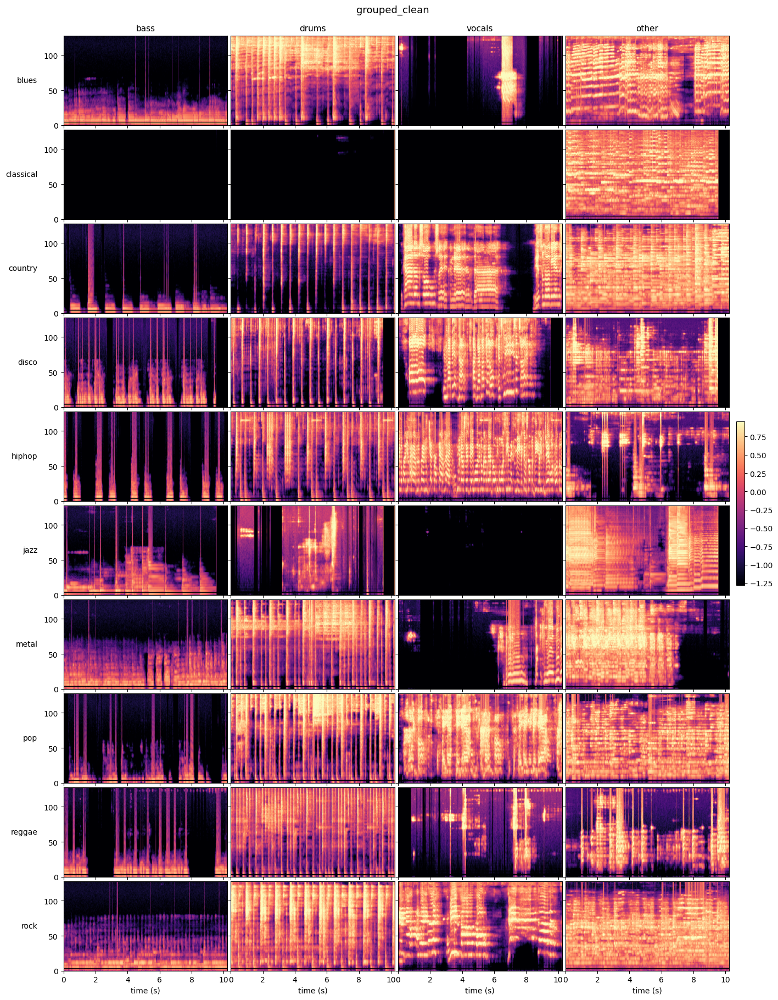

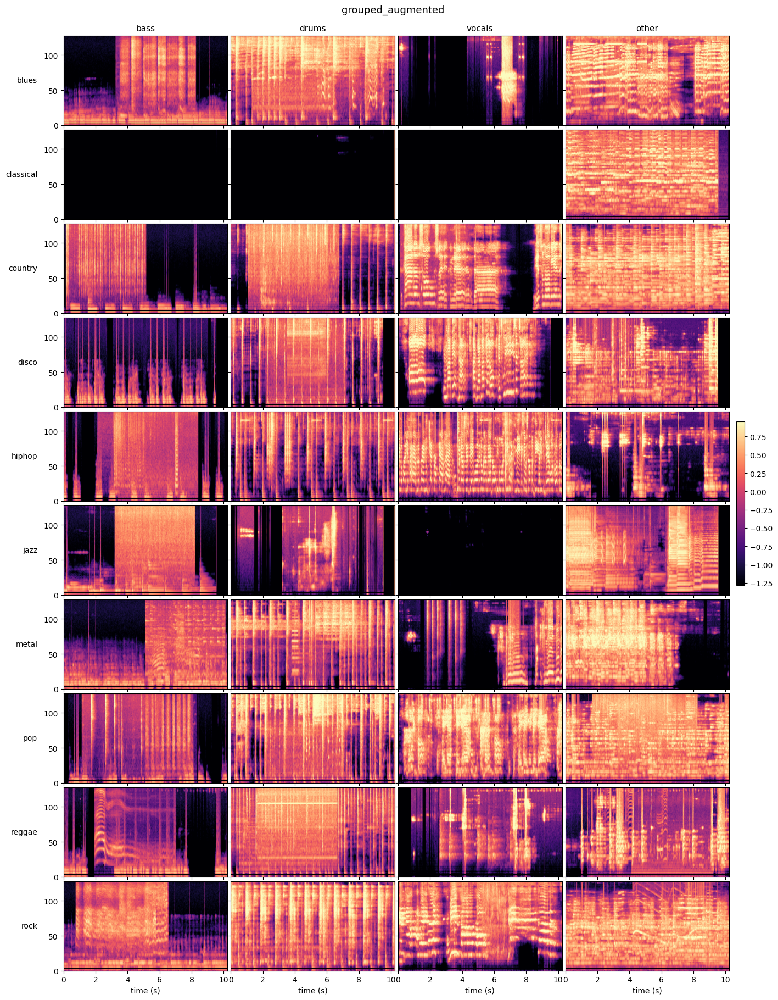

(-1.27734375, 0.95654296875)

In [16]:
# 3) grouped variants (each file already holds all 4 stems)
plot_genre_stem_grid(GENRES_PT / "grouped_clean", vmin=vmin, vmax=vmax, title="grouped_clean")
plot_genre_stem_grid(GENRES_PT / "grouped_augmented", vmin=vmin, vmax=vmax, title="grouped_augmented")

In [17]:
# 4) save every grid as a PNG (nothing is displayed)
run_all(GENRES_PT, out_dir="eda_plots", show=False)

/tmp/ipykernel_365307/4034304327.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  spec, label, stem_id = torch.load(path, map_location="cpu")


saved: eda_plots/flattened_clean.png
saved: eda_plots/flattened_augmented.png
saved: eda_plots/grouped_clean.png
saved: eda_plots/grouped_augmented.png
saved: eda_plots/flattened_clean_vs_augmented.png
saved: eda_plots/grouped_clean_vs_augmented.png
